# Named actor: create, look up, call and kill

A detached actor is registered under a name, looked up again with ray.get_actor, called, and finally removed with ray.kill.

**When to use it.** Services shared across jobs or notebooks (a model cache, a coordinator) that other code finds by name.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

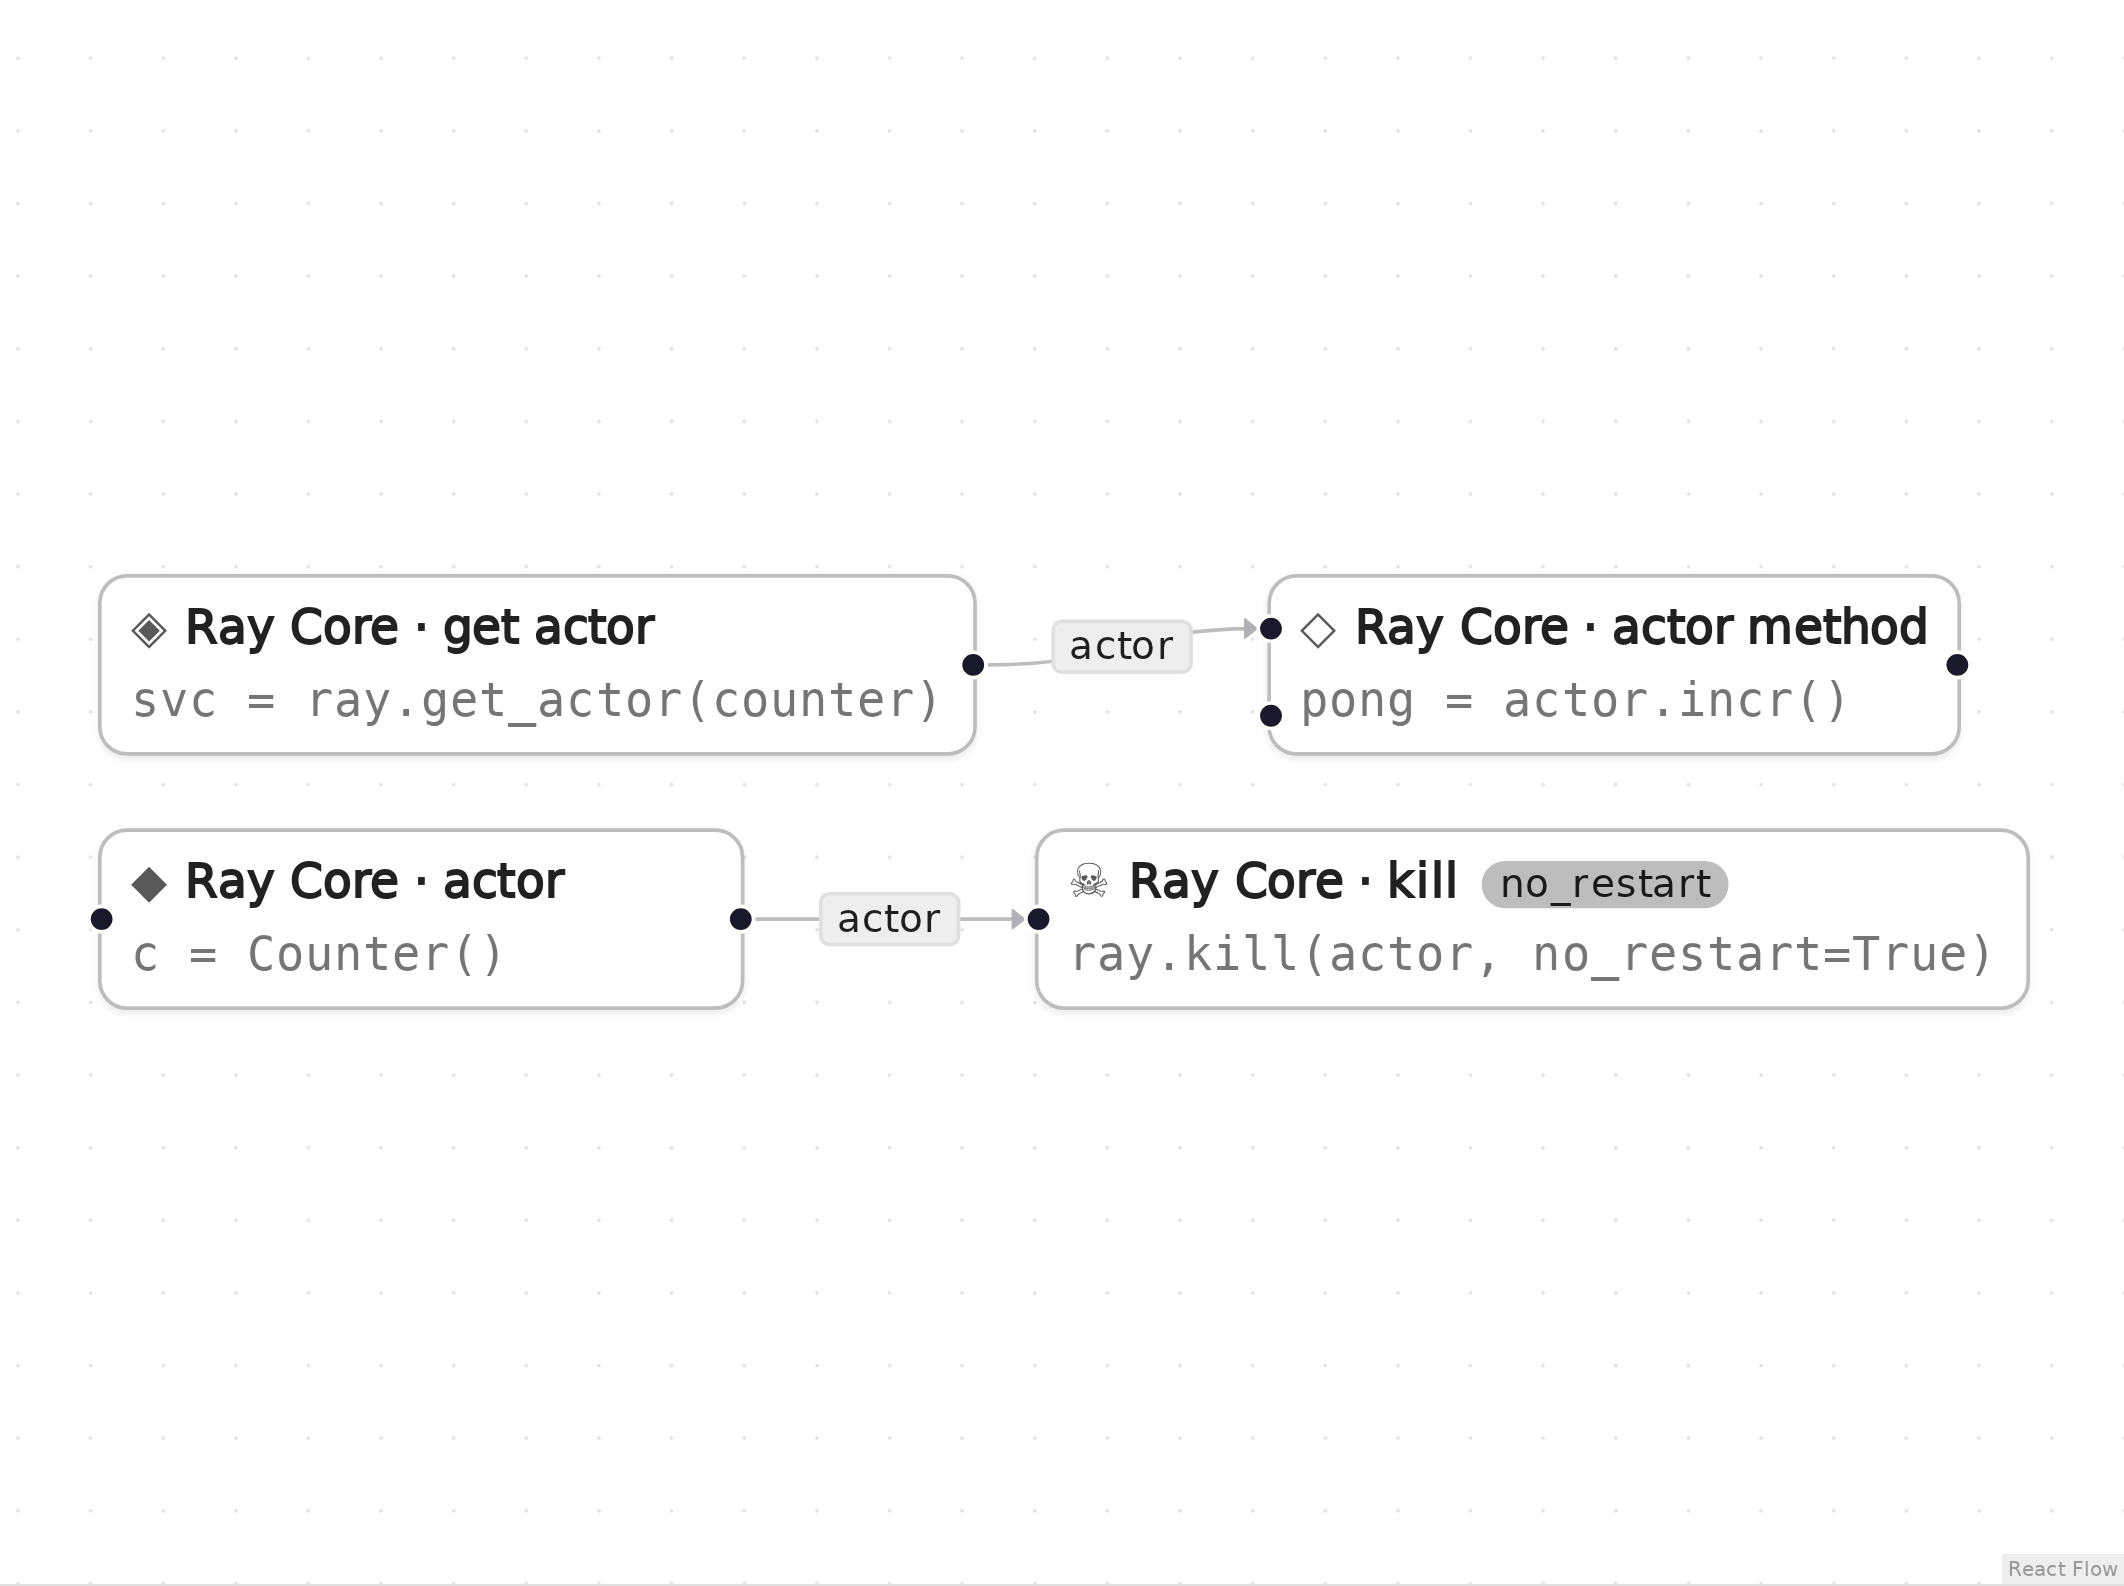

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
class Counter:
    def __init__(self):
        self.n = 0

    def incr(self):
        self.n += 1
        return self.n

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

c = ray.remote(Counter).options(name="counter", lifetime="detached", get_if_exists=True).remote()
svc = ray.get_actor("counter")
_m1 = svc.incr.remote()
pong = ray.get(_m1)
ray.kill(c, no_restart=True)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import time

assert pong == 1, pong
for _ in range(100):
    try:
        ray.get_actor("counter")
    except ValueError:
        break
    time.sleep(0.1)
else:
    raise AssertionError("the actor is still registered after ray.kill")
print("pong =", pong, "; actor removed")

pong = 1 ; actor removed


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Actor** (node `a1`, line 8)

```python
c = ray.remote(Counter).options(name="counter", lifetime="detached", get_if_exists=True).remote()
```

name="counter" registers the actor, lifetime="detached" keeps it alive after the driver exits, and get_if_exists=True reuses an existing one instead of failing.

**Get actor** (node `g1`, line 9)

```python
svc = ray.get_actor("counter")
```

ray.get_actor finds the actor by name, the way another job or notebook would.

**Actor method** (node `m1`, lines 10–11)

```python
_m1 = svc.incr.remote()
pong = ray.get(_m1)
```

Calls incr through the looked-up handle.

**Kill actor** (node `k1`, line 12)

```python
ray.kill(c, no_restart=True)
```

ray.kill removes the detached actor; no_restart=True stops Ray from restarting it.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()